In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("../data/forest+fires/forestfires.csv", delimiter=",")
print("Shape: ", df.shape)
df.info()
print(df.describe(include="all").T)
print(df.isna().mean().sort_values(ascending=False))
print(df.nunique().sort_values())
print(df[df.duplicated()])
print("Duplicates: ", df.duplicated().sum())


Shape:  (517, 13)
<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB
       count unique  top freq        mean         std   min    25%    50%  \
X      517.0    NaN  NaN  NaN    4.669246    2.313778   1.0    3.0    4.0   
Y      517.0    NaN  NaN  NaN    4.299807      1.2299   2.0    4.0    4.0   
month    517     12  aug  184         NaN  

Results:
Shape:  (517, 13)
<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB
       count unique  top freq        mean         std   min    25%    50%  \
X      517.0    NaN  NaN  NaN    4.669246    2.313778   1.0    3.0    4.0   
Y      517.0    NaN  NaN  NaN    4.299807      1.2299   2.0    4.0    4.0   
month    517     12  aug  184         NaN         NaN   NaN    NaN    NaN   
day      517      7  sun   95         NaN         NaN   NaN    NaN    NaN   
FFMC   517.0    NaN  NaN  NaN   90.644681    5.520111  18.7   90.2   91.6   
DMC    517.0    NaN  NaN  NaN   110.87234   64.046482   1.1   68.6  108.3   
DC     517.0    NaN  NaN  NaN  547.940039  248.066192   7.9  437.7  664.2   
ISI    517.0    NaN  NaN  NaN    9.021663    4.559477   0.0    6.5    8.4   
temp   517.0    NaN  NaN  NaN   18.889168    5.806625   2.2   15.5   19.3   
RH     517.0    NaN  NaN  NaN   44.288201   16.317469  15.0   33.0   42.0   
wind   517.0    NaN  NaN  NaN    4.017602    1.791653   0.4    2.7    4.0   
rain   517.0    NaN  NaN  NaN    0.021663    0.295959   0.0    0.0    0.0   
area   517.0    NaN  NaN  NaN   12.847292   63.655818   0.0    0.0   0.52   

         75%      max  
X        7.0      9.0  
Y        5.0      9.0  
month    NaN      NaN  
day      NaN      NaN  
FFMC    92.9     96.2  
DMC    142.4    291.3  
DC     713.9    860.6  
ISI     10.8     56.1  
temp    22.8     33.3  
RH      53.0    100.0  
wind     4.9      9.4  
rain     0.0      6.4  
area    6.57  1090.84  
X        0.0
Y        0.0
month    0.0
day      0.0
FFMC     0.0
DMC      0.0
DC       0.0
ISI      0.0
temp     0.0
RH       0.0
wind     0.0
rain     0.0
area     0.0
dtype: float64
Y          7
day        7
rain       7
X          9
month     12
wind      21
RH        75
FFMC     106
ISI      119
temp     192
DMC      215
DC       219
area     251
dtype: int64
     X  Y month  day  FFMC    DMC     DC   ISI  temp  RH  wind  rain   area
53   4  3   aug  wed  92.1  111.2  654.1   9.6  20.4  42   4.9   0.0   0.00
100  3  4   aug  sun  91.4  142.4  601.4  10.6  19.8  39   5.4   0.0   0.00
215  4  4   mar  sat  91.7   35.8   80.8   7.8  17.0  27   4.9   0.0  28.66
303  3  6   jun  fri  91.1   94.1  232.1   7.1  19.2  38   4.5   0.0   0.00
Duplicates:  4


Discard days, not relevant data
Possibly discard months, as they are used to determine the DMC and DC scores. Therefore, their relevance is already accounted for.
Getting BUI and FWI could possibly allow in removing some of the other columns.
Normalise area as it is very skewed towards 0.
Remove duplicates.
Figure out most influential subset of data


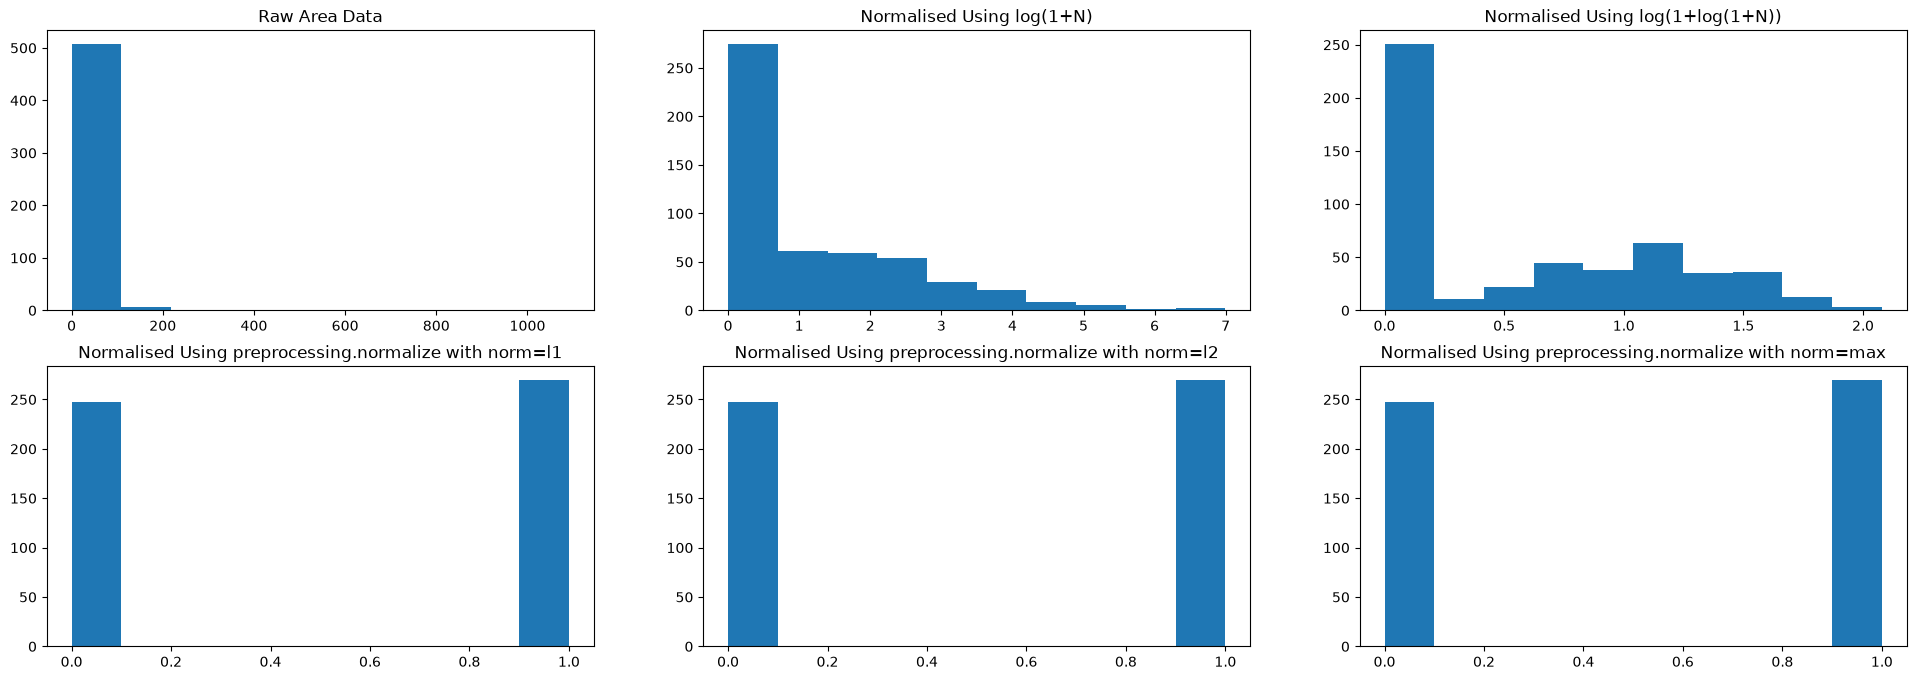

In [36]:
from sklearn import preprocessing
# Trying some normalisation for area
plt.figure(figsize=(24,8))

plt.subplot(231, title = "Raw Area Data").hist(df["area"])

plt.subplot(232, title = "Normalised Using log(1+N)").hist(np.log1p(df["area"]))

plt.subplot(233, title = "Normalised Using log(1+log(1+N))").hist(np.log1p(np.log1p(df["area"])))

plt.subplot(234, title = "Normalised Using preprocessing.normalize with norm=l1").hist(preprocessing.normalize(df[["area"]], norm='l1'))
plt.subplot(235, title = "Normalised Using preprocessing.normalize with norm=l2").hist(preprocessing.normalize(df[["area"]], norm='l2'))
plt.subplot(236, title = "Normalised Using preprocessing.normalize with norm=max").hist(preprocessing.normalize(df[["area"]], norm='max'))

plt.show()

How to calculate Fire Weather Index Values: https://publications.gc.ca/collections/collection_2016/rncan-nrcan/Fo133-1-424-eng.pdf